In [1]:
import regex as re
from tqdm.auto import tqdm
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report

from scipy import stats

from matplotlib import pyplot as plt
import mpl_toolkits.axisartist.axislines as axislines
import matplotlib.transforms as mtransforms
import matplotlib.lines

from statsmodels.formula.api import ols, logit
from stargazer.stargazer import Stargazer

C:\Users\isen1\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
# style helpers 

def clean_name(v):
    m = re.search(r'\[T\.(.*)\]', v)
    val = m.group(1) if m else v
    grp_m = re.search(r'C\((\w+)\)', v)
    grp = grp_m.group(1).replace('_', ' ') if grp_m else ''
    return f'{grp}: {val}' if grp else val

def pretty_label(name):
    return name.replace('_', ' ').title()

In [3]:
# ideology helpers

def reoder_ideology_order(current_labels):
    final_labels = [current_labels[0]]

    conservative_labels = []
    liberal_labels = []
    moderate_labels = []

    for label in current_labels:
        if 'conserv' in label.lower():
            conservative_labels.append(label)
        if 'moderate' in label.lower():
            moderate_labels.append(label)
        if 'lib' in label.lower():
            liberal_labels.append(label)
        
    final_labels = final_labels + sorted(liberal_labels) +\
    sorted(moderate_labels) + [conservative_labels[-1]] + conservative_labels[:2]
    return final_labels

def ideology_color(raw_label):
    text = raw_label.lower()
    if 'conserv' in text:
        return IDEOLOGY_COLORS['conservative']
    if 'lib' in text:
        return IDEOLOGY_COLORS['liberal']
    if 'moderate' in text:
        return IDEOLOGY_COLORS['moderate']
    return IDEOLOGY_COLORS['overall']

In [4]:
agg_results_df = pd.read_csv('results/pre_election/evaluated_results_subgroup_nonadjusted.csv')

In [5]:
agg_results_df = agg_results_df.rename(columns={
    'nonadjusted_weighted_avg': 'nonadjusted_weighted_tvd',
    'adjusted_weighted_avg': 'adjusted_weighted_tvd',
})

In [6]:
plot_df = agg_results_df.copy()
plot_df['Survey Question'] = plot_df.questionnaire_item_id.replace({1: 'Version 1', 2: 'Version 2'})
plot_df['response_type'] = plot_df.response_type.replace({'jsonResponse': 'JSON structured output', 'openResponse': 'open-ended response'})
plot_df['parsing_method'] = plot_df.parsing_method.replace({'jsonParsing': 'JSON parsing', 'regex': 'regex parsing', 'LLMjudge': 'LLM-as-a-judge'})
plot_df['Persona Information'] = plot_df.persona_format.apply(lambda x:'demographic only' if 'demogr' in x else 'demographics & attitudes')
plot_df['Persona Format'] = plot_df.persona_format.apply(lambda x:'direct' if 'Person' in x else 'interview')

plot_df = plot_df.drop(columns=['questionnaire_item_id', 'persona_format', 'sample'])
plot_df = plot_df.rename(columns={
    'response_type': 'Output Generation',
    'model_id': 'LLM model ID',
    'parsing_method': 'Output Parsing',
})

In [7]:
indep_vars = ['Output Generation', 'LLM model ID', 'Output Parsing', 'Survey Question', 'Persona Information',
       'Persona Format']

In [8]:
plot_df = plot_df.rename(columns={i : '_'.join(i.split()) for i in indep_vars})
indep_vars = ['_'.join(i.split()) for i in indep_vars]
plot_df[indep_vars]

,Output_Generation,LLM_model_ID,Output_Parsing,Survey_Question,Persona_Information,Persona_Format
0,JSON structured output,Llama-3.1-8B-Instruct,JSON parsing,Version 1,demographic only,direct
1,JSON structured output,Llama-3.3-70B-Instruct,JSON parsing,Version 1,demographic only,direct
2,JSON structured output,Olmo-3-7B-Instruct,JSON parsing,Version 1,demographic only,direct
3,JSON structured output,Olmo-3.1-32B-Instruct,JSON parsing,Version 1,demographic only,direct
4,JSON structured output,Qwen3-VL-30B-A3B-Instruct,JSON parsing,Version 1,demographic only,direct
...,...,...,...,...,...,...
139,open-ended response,Olmo-3.1-32B-Instruct,regex parsing,Version 2,demographics & attitudes,interview
140,open-ended response,Qwen3-VL-30B-A3B-Instruct,LLM-as-a-judge,Version 2,demographics & attitudes,interview
141,open-ended response,Qwen3-VL-30B-A3B-Instruct,regex parsing,Version 2,demographics & attitudes,interview
142,open-ended response,Qwen3-VL-8B-Instruct,LLM-as-a-judge,Version 2,demographics & attitudes,interview


In [9]:
for var in indep_vars:
    print(var)
    print(plot_df[var].unique())

Output_Generation
['JSON structured output' 'open-ended response']
LLM_model_ID
['Llama-3.1-8B-Instruct' 'Llama-3.3-70B-Instruct' 'Olmo-3-7B-Instruct'
 'Olmo-3.1-32B-Instruct' 'Qwen3-VL-30B-A3B-Instruct'
 'Qwen3-VL-8B-Instruct']
Output_Parsing
['JSON parsing' 'LLM-as-a-judge' 'regex parsing']
Survey_Question
['Version 1' 'Version 2']
Persona_Information
['demographic only' 'demographics & attitudes']
Persona_Format
['direct' 'interview']


In [10]:
og_dict = {'JSON structured output': 'JSON',
           'open-ended response' : 'free-text'}
model_dict = {'Llama-3.1-8B-Instruct': 'Llama-8B',
              'Llama-3.3-70B-Instruct': 'Llama-70B',
              'Olmo-3-7B-Instruct': 'Olmo-7B',
              'Olmo-3.1-32B-Instruct': 'Olmo-32B',
              'Qwen3-VL-30B-A3B-Instruct': 'Qwen-30B',
              'Qwen3-VL-8B-Instruct': 'Qwen-8B'
             }
op_dict = {'JSON parsing': 'JSON_parsing',
           'LLM-as-a-judge': 'LLM judge',
           'regex parsing': 'regex'}

sq_dict = {'Version 1' : 'v1',
           'Version 2' : 'v2'}

pi_dict = {'demographic only': 'demo',
      'demographics & attitudes' : 'demo+att'}

pf_dict = {'direct' : 'direct',
           'interview' : 'interview'}

In [11]:
### rename everything

og = []
models = []
op = []
sq = []
pi = []
pf = []

for _, row in plot_df.iterrows():
    og.append(og_dict[row['Output_Generation']])
    models.append(model_dict[row['LLM_model_ID']])
    op.append(op_dict[row['Output_Parsing']])
    sq.append(sq_dict[row['Survey_Question']])
    pi.append(pi_dict[row['Persona_Information']])
    pf.append(pf_dict[row['Persona_Format']])
    
plot_df['Output_Generation'] = og
plot_df['LLM_model_ID'] = models
plot_df['Output_Parsing'] = op
plot_df['Survey_Question'] = sq
plot_df['Persona_Information'] = pi
plot_df['Persona_Format'] = pf

In [12]:
### combine persona_format and persona_info into persona construction
plot_df['Persona'] = plot_df['Persona_Information'] + ' (' + plot_df['Persona_Format']  + ')'

In [13]:
plot_df = plot_df.rename(columns = {'Output_Generation': 'Inference',
                                    'LLM_model_ID': 'LLM',
                                    'Output_Parsing': 'Behavior_Proc',
                                    'Survey_Question': 'Task',
                                    })
indep_vars = ['Inference',
'LLM',
    'Behavior_Proc',
    'Task',
    'Persona'
    ]

In [14]:
# Response Generation (Inference) and Response Processing (Behavior_Proc) are
# structurally confounded: JSON parsing only ever occurs with JSON-structured
# output, and regex/LLM-judge parsing only ever occur with free-text output.
# Modeling them as two separate main effects makes the design matrix
# rank-deficient (the "covariance of constraints does not have full rank"
# warning) and the individual coefficients are not uniquely identified. Merge
# them into a single factor, the same way Persona_Information + Persona_Format
# were merged into Persona above.
plot_df['Response_Handling'] = plot_df['Inference'] + ' + ' + plot_df['Behavior_Proc']
indep_vars = ['Response_Handling', 'LLM', 'Task', 'Persona']

In [15]:
plot_df = plot_df.rename(columns = {'f1_Non-voter' : 'f1_Non_voter'})

In [16]:
plot_df.columns

Index(['Inference', 'LLM', 'Behavior_Proc', 'simulated_responses',
       'valid_responses', 'accuracy', 'weighted_accuracy', 'macro_avg_f1',
       'nonadjusted_weighted_f1', 'adjusted_weighted_f1', 'f1_Trump',
       'f1_Harris', 'f1_Non_voter', 'nonadjusted_weighted_tvd',
       'nonadjusted_weighted_std', 'adjusted_weighted_tvd',
       'adjusted_weighted_std', 'nonadjusted_weighted10_avg',
       'nonadjusted_weighted10_std', 'adjusted_weighted10_avg',
       'adjusted_weighted10_std', 'nonadjusted_weighted50_avg',
       'nonadjusted_weighted50_std', 'adjusted_weighted50_avg',
       'adjusted_weighted50_std', 'nonadjusted_weighted100_avg',
       'nonadjusted_weighted100_std', 'adjusted_weighted100_avg',
       'adjusted_weighted100_std', 'adjusted_weighted_f1_gender_female',
       'nonadjusted_weighted_f1_gender_female',
       'adjusted_weighted_tvd_gender_female',
       'nonadjusted_weighted_tvd_gender_female',
       'adjusted_weighted_f1_gender_male',
       'nonadjusted_

### pivot table to make adjustment a decision choice

In [17]:
plot_df

,Inference,LLM,Behavior_Proc,simulated_responses,valid_responses,accuracy,weighted_accuracy,macro_avg_f1,nonadjusted_weighted_f1,adjusted_weighted_f1,...,nonadjusted_weighted_tvd_ideology_slightly conservative,adjusted_weighted_f1_ideology_slightly liberal,nonadjusted_weighted_f1_ideology_slightly liberal,adjusted_weighted_tvd_ideology_slightly liberal,nonadjusted_weighted_tvd_ideology_slightly liberal,Task,Persona_Information,Persona_Format,Persona,Response_Handling
0,JSON,Llama-8B,JSON_parsing,25355,25355,0.510392,0.525109,0.359894,0.468438,0.481758,...,0.110078,0.501261,0.420632,0.480081,0.578927,v1,demo,direct,demo (direct),JSON + JSON_parsing
1,JSON,Llama-70B,JSON_parsing,25355,25355,0.535831,0.538787,0.378578,0.500140,0.495360,...,0.116279,0.563793,0.505534,0.390708,0.480843,v1,demo,direct,demo (direct),JSON + JSON_parsing
2,JSON,Olmo-7B,JSON_parsing,25355,25355,0.440032,0.439604,0.268980,0.341858,0.347520,...,0.281395,0.281890,0.214116,0.744047,0.781992,v1,demo,direct,demo (direct),JSON + JSON_parsing
3,JSON,Olmo-32B,JSON_parsing,25355,25355,0.515283,0.521447,0.405387,0.503052,0.506309,...,0.080233,0.594110,0.529471,0.327463,0.415326,v1,demo,direct,demo (direct),JSON + JSON_parsing
4,JSON,Qwen-30B,JSON_parsing,25355,25355,0.537961,0.534316,0.398808,0.514614,0.503264,...,0.199612,0.625385,0.568441,0.298977,0.383908,v1,demo,direct,demo (direct),JSON + JSON_parsing
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,free-text,Olmo-32B,regex,25355,23737,NaN,NaN,0.597095,0.773980,0.733321,...,0.115698,0.828960,0.859828,0.051525,0.039272,v2,demo+att,interview,demo+att (interview),free-text + regex
140,free-text,Qwen-30B,LLM judge,25355,25355,0.802011,0.769048,0.581513,0.757026,0.710927,...,0.115116,0.814936,0.841627,0.116739,0.100383,v2,demo+att,interview,demo+att (interview),free-text + LLM judge
141,free-text,Qwen-30B,regex,25355,25277,NaN,NaN,0.565786,0.751721,0.705273,...,0.115698,0.814936,0.841627,0.116739,0.100383,v2,demo+att,interview,demo+att (interview),free-text + regex
142,free-text,Qwen-8B,LLM judge,25355,25355,0.781266,0.762095,0.589525,0.745610,0.718261,...,0.265891,0.777683,0.790379,0.131611,0.130268,v2,demo+att,interview,demo+att (interview),free-text + LLM judge


In [18]:
# The evaluation results store "adjustment" (whether survey/demographic
# weights were used when computing a metric) as parallel columns rather than
# as its own decision choice: f1, tvd, and the gender/ideology subgroup
# metrics are all split into adjusted_<x>/nonadjusted_<x> column pairs.
# Melt every such pair into a single metric column plus a new 'Adjustment'
# decision-choice column.
adjusted_cols = [c for c in plot_df.columns if c.startswith('adjusted_')]
paired_cols = {}
for adj_col in adjusted_cols:
    base = adj_col[len('adjusted_'):]
    nonadj_col = f'nonadjusted_{base}'
    if nonadj_col in plot_df.columns:
        paired_cols[base] = (adj_col, nonadj_col)

paired_flat = {c for pair in paired_cols.values() for c in pair}
id_cols = [c for c in plot_df.columns if c not in paired_flat]

adjusted_df = plot_df[id_cols + [adj for adj, _ in paired_cols.values()]].rename(
    columns={adj: base for base, (adj, _) in paired_cols.items()}).copy()
adjusted_df['Adjustment'] = 'adjusted'

nonadjusted_df = plot_df[id_cols + [nonadj for _, nonadj in paired_cols.values()]].rename(
    columns={nonadj: base for base, (_, nonadj) in paired_cols.items()}).copy()
nonadjusted_df['Adjustment'] = 'non-adjusted'

plot_df = pd.concat([adjusted_df, nonadjusted_df], ignore_index=True)
indep_vars = indep_vars + ['Adjustment']

# from here on, the regressions use the two pivoted (unprefixed) metric names
metrics_for_table = ['weighted_f1', 'weighted_tvd']
plot_df

,Inference,LLM,Behavior_Proc,simulated_responses,valid_responses,accuracy,weighted_accuracy,macro_avg_f1,f1_Trump,f1_Harris,...,weighted_tvd_ideology_extremely liberal,weighted_f1_ideology_liberal,weighted_tvd_ideology_liberal,weighted_f1_ideology_moderate,weighted_tvd_ideology_moderate,weighted_f1_ideology_slightly conservative,weighted_tvd_ideology_slightly conservative,weighted_f1_ideology_slightly liberal,weighted_tvd_ideology_slightly liberal,Adjustment
0,JSON,Llama-8B,JSON_parsing,25355,25355,0.510392,0.525109,0.359894,0.593407,0.473064,...,0.460800,0.557685,0.493601,0.405129,0.258451,0.546364,0.123127,0.501261,0.480081,adjusted
1,JSON,Llama-70B,JSON_parsing,25355,25355,0.535831,0.538787,0.378578,0.591929,0.542434,...,0.294532,0.653596,0.373691,0.420454,0.211938,0.533803,0.200065,0.563793,0.390708,adjusted
2,JSON,Olmo-7B,JSON_parsing,25355,25355,0.440032,0.439604,0.268980,0.577623,0.227955,...,0.738040,0.291902,0.775689,0.239734,0.598726,0.500125,0.265309,0.281890,0.744047,adjusted
3,JSON,Olmo-32B,JSON_parsing,25355,25355,0.515283,0.521447,0.405387,0.567246,0.544390,...,0.276535,0.644230,0.359694,0.453073,0.140405,0.545377,0.138609,0.594110,0.327463,adjusted
4,JSON,Qwen-30B,JSON_parsing,25355,25355,0.537961,0.534316,0.398808,0.570651,0.579105,...,0.223819,0.696377,0.299174,0.436036,0.172277,0.509939,0.284801,0.625385,0.298977,adjusted
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,free-text,Olmo-32B,regex,25355,23737,NaN,NaN,0.597095,0.856814,0.874607,...,0.049123,0.923909,0.033665,0.658706,0.111576,0.678287,0.115698,0.859828,0.039272,non-adjusted
284,free-text,Qwen-30B,LLM judge,25355,25355,0.802011,0.769048,0.581513,0.843241,0.853775,...,0.107018,0.922031,0.052174,0.636496,0.158949,0.654074,0.115116,0.841627,0.100383,non-adjusted
285,free-text,Qwen-30B,regex,25355,25277,NaN,NaN,0.565786,0.843446,0.853912,...,0.107018,0.920753,0.053043,0.630946,0.160700,0.652913,0.115698,0.841627,0.100383,non-adjusted
286,free-text,Qwen-8B,LLM judge,25355,25355,0.781266,0.762095,0.589525,0.807096,0.843348,...,0.063158,0.923844,0.040000,0.613170,0.221401,0.603008,0.265891,0.790379,0.130268,non-adjusted


## descriptive results

- overall performance and best-performing design choice variant
- difference between best and worst design configuration
- is the best configuration the same between both metrics
- rank correlation between tvd and f1 rankings of configs

In [19]:
mean = {}
std = {}
for metric in metrics_for_table:
    mean[metric] = {}
    std[metric] = {}
    for var in indep_vars:
        mean[metric][var] = dict(plot_df.groupby(var).mean(numeric_only = True)[metric])
        std[metric][var] = dict(plot_df.groupby(var).std(numeric_only = True)[metric])

In [20]:
table = {}
for metric in metrics_for_table:
    df_rows = []
    for var in mean[metric]:
        for var2 in mean[metric][var]:
            num = str(mean[metric][var][var2].round(3)) + ' \u00B1 ' + str(std[metric][var][var2].round(2))
            df_rows.append([var, var2, num])
    
    num = str(plot_df.mean(numeric_only = True)[metric].round(3)) + ' \u00B1 ' \
          + str(plot_df.std(numeric_only = True)[metric].round(2))
    df_rows.append(['Overall', 'Overall', num])
    table[metric] = pd.DataFrame(df_rows)
    table[metric].columns = ['Design Choice', 'Variant', '%s' %(metric)]
    
table_df = table[metrics_for_table[0]]
for metric in metrics_for_table[1:]:
    table_df = table_df.merge(table[metric])

In [21]:
table_df

,Design Choice,Variant,weighted_f1,weighted_tvd
0,Response_Handling,JSON + JSON_parsing,0.615 ± 0.15,0.227 ± 0.1
1,Response_Handling,free-text + LLM judge,0.609 ± 0.15,0.202 ± 0.09
2,Response_Handling,free-text + regex,0.59 ± 0.13,0.209 ± 0.08
3,LLM,Llama-70B,0.626 ± 0.13,0.208 ± 0.06
4,LLM,Llama-8B,0.593 ± 0.12,0.197 ± 0.07
5,LLM,Olmo-32B,0.619 ± 0.17,0.171 ± 0.09
6,LLM,Olmo-7B,0.549 ± 0.15,0.267 ± 0.13
7,LLM,Qwen-30B,0.629 ± 0.14,0.206 ± 0.08
8,LLM,Qwen-8B,0.614 ± 0.13,0.226 ± 0.08
9,Task,v1,0.606 ± 0.14,0.212 ± 0.09


In [22]:
print(table_df.to_latex())

\begin{tabular}{lllll}
\toprule
 & Design Choice & Variant & weighted_f1 & weighted_tvd \\
\midrule
0 & Response_Handling & JSON + JSON_parsing & 0.615 ± 0.15 & 0.227 ± 0.1 \\
1 & Response_Handling & free-text + LLM judge & 0.609 ± 0.15 & 0.202 ± 0.09 \\
2 & Response_Handling & free-text + regex & 0.59 ± 0.13 & 0.209 ± 0.08 \\
3 & LLM & Llama-70B & 0.626 ± 0.13 & 0.208 ± 0.06 \\
4 & LLM & Llama-8B & 0.593 ± 0.12 & 0.197 ± 0.07 \\
5 & LLM & Olmo-32B & 0.619 ± 0.17 & 0.171 ± 0.09 \\
6 & LLM & Olmo-7B & 0.549 ± 0.15 & 0.267 ± 0.13 \\
7 & LLM & Qwen-30B & 0.629 ± 0.14 & 0.206 ± 0.08 \\
8 & LLM & Qwen-8B & 0.614 ± 0.13 & 0.226 ± 0.08 \\
9 & Task & v1 & 0.606 ± 0.14 & 0.212 ± 0.09 \\
10 & Task & v2 & 0.604 ± 0.14 & 0.213 ± 0.09 \\
11 & Persona & demo (direct) & 0.474 ± 0.04 & 0.268 ± 0.06 \\
12 & Persona & demo (interview) & 0.465 ± 0.05 & 0.303 ± 0.07 \\
13 & Persona & demo+att (direct) & 0.75 ± 0.04 & 0.126 ± 0.03 \\
14 & Persona & demo+att (interview) & 0.731 ± 0.05 & 0.153 ± 0.04 \\
15 &

In [23]:
# best and worst configuration
best = {}
worst = {}
for metric in metrics_for_table:
    if 'tvd' in metric:
        best[metric+'_config_id'] = plot_df.sort_values(metric).index[0]
        worst[metric+'_config_id'] = plot_df.sort_values(metric).index[-1]
        best[metric+'_config'] = plot_df.sort_values(metric)[indep_vars].iloc[0]
        worst[metric+'_config'] = plot_df.sort_values(metric)[indep_vars].iloc[-1]
        best[metric+'_val'] = plot_df.sort_values(metric)[metric].iloc[0]
        worst[metric+'_val'] = plot_df.sort_values(metric)[metric].iloc[-1]
    else:
        best[metric+'_config_id'] = plot_df.sort_values(metric, ascending=False).index[0]
        worst[metric+'_config_id'] = plot_df.sort_values(metric, ascending=False).index[-1]
        best[metric+'_config'] = plot_df.sort_values(metric, ascending=False)[indep_vars].iloc[0]
        worst[metric+'_config'] = plot_df.sort_values(metric, ascending=False)[indep_vars].iloc[-1]
        best[metric+'_val'] = plot_df.sort_values(metric, ascending=False)[metric].iloc[0]
        worst[metric+'_val'] = plot_df.sort_values(metric, ascending=False)[metric].iloc[-1]

In [24]:
best

{'weighted_f1_config_id': 237,
 'weighted_f1_config': Response_Handling     JSON + JSON_parsing
 LLM                              Olmo-32B
 Task                                   v2
 Persona              demo+att (interview)
 Adjustment                   non-adjusted
 Name: 237, dtype: object,
 'weighted_f1_val': 0.8278609685627815,
 'weighted_tvd_config_id': 282,
 'weighted_tvd_config': Response_Handling    free-text + LLM judge
 LLM                               Olmo-32B
 Task                                    v2
 Persona               demo+att (interview)
 Adjustment                    non-adjusted
 Name: 282, dtype: object,
 'weighted_tvd_val': 0.0600178451783241}

In [25]:
worst

{'weighted_f1_config_id': 256,
 'weighted_f1_config': Response_Handling    free-text + LLM judge
 LLM                                Olmo-7B
 Task                                    v2
 Persona                   demo (interview)
 Adjustment                    non-adjusted
 Name: 256, dtype: object,
 'weighted_f1_val': 0.3375842994782519,
 'weighted_tvd_config_id': 146,
 'weighted_tvd_config': Response_Handling    JSON + JSON_parsing
 LLM                              Olmo-7B
 Task                                  v1
 Persona                    demo (direct)
 Adjustment                  non-adjusted
 Name: 146, dtype: object,
 'weighted_tvd_val': 0.506028170073062}

In [26]:
stats.spearmanr(plot_df['weighted_f1'], plot_df['weighted_tvd'])

SignificanceResult(statistic=-0.8615283990210145, pvalue=3.4956661667806685e-86)

## regressions for determining impact of design choices

In [27]:
metrics_for_table

['weighted_f1', 'weighted_tvd']

In [28]:
main_metric = metrics_for_table[1]

In [29]:
# get the reference categories: for each design choice, the variant that
# achieves the highest mean on the main metric, flip for TVD

if 'tvd' in main_metric:
    refs = {
        var: plot_df.groupby(var)[main_metric].mean().idxmin()
        for var in indep_vars
    }
else:
    refs = {
        var: plot_df.groupby(var)[main_metric].mean().idxmax()
        for var in indep_vars
    }
refs

{'Response_Handling': 'free-text + LLM judge',
 'LLM': 'Olmo-32B',
 'Task': 'v1',
 'Persona': 'demo+att (direct)',
 'Adjustment': 'non-adjusted'}

In [30]:
formula = ''
for var in indep_vars:
    formula = formula + 'C(' + var + ', Treatment(reference=\'' + refs[var] + '\'))+'
    
formula = formula[:-1]

In [31]:
formula

"C(Response_Handling, Treatment(reference='free-text + LLM judge'))+C(LLM, Treatment(reference='Olmo-32B'))+C(Task, Treatment(reference='v1'))+C(Persona, Treatment(reference='demo+att (direct)'))+C(Adjustment, Treatment(reference='non-adjusted'))"

In [32]:
### create aregression plot broken down by gender subgroup
### works for any metric of interest (F1 or TVD), not just F1 -- see subgroup_metric below

In [33]:
# Which per-subgroup metric family the gender/ideology figures below break
# down by -- derived from main_metric so switching main_metric to 'weighted_tvd'
# automatically switches every subgroup figure to use the
# weighted_tvd_gender_*/weighted_tvd_ideology_* columns instead of
# weighted_f1_gender_*/weighted_f1_ideology_*,
# with no other code changes needed.

subgroup_metric = main_metric

# label the gender (sex) categories as groups ("male" -> "Men"),
# fall back to the raw category name
CATEGORY_LABEL_FIXES = {'male': 'men', 'female': 'women'}

In [34]:
# discover the gender subgroup columns for the chosen metric rather than hardcoding their names
gender_cols = [c for c in plot_df.columns if c.startswith(f'{subgroup_metric}_gender_')]
gender_categories = {c: c.replace(f'{subgroup_metric}_gender_', '') for c in gender_cols}
gender_rename = {
    c: f'{subgroup_metric.upper()}_' + CATEGORY_LABEL_FIXES.get(cat, cat).replace(' ', '_')
    for c, cat in gender_categories.items()
}

plot_df_gender = plot_df.rename(columns=gender_rename)

dep_vars_gender = [main_metric] + list(gender_rename.values())

regs_gender = []
for dep_var in dep_vars_gender:
    regs_gender.append(ols(f"{dep_var} ~ {formula}",
          data = plot_df_gender).fit(cov_type = 'HC3'))

In [35]:
model_labels_gender_raw = ['Overall'] + [
    f'{CATEGORY_LABEL_FIXES.get(cat, cat).title()}'
    for cat in gender_categories.values()
]

all_coefs_gender = []
for reg, label in zip(regs_gender, model_labels_gender_raw):
    ci = reg.conf_int()
    df_c = pd.DataFrame({
        'coef': reg.params,
        'ci_low': ci[0],
        'ci_high': ci[1],
        'pvalue': reg.pvalues,
        'model': label
    })
    df_c = df_c[df_c.index != 'Intercept']
    all_coefs_gender.append(df_c)

coef_df_gender = pd.concat(all_coefs_gender).reset_index().rename(columns={'index': 'variable'})
coef_df_gender['label'] = coef_df_gender['variable'].apply(clean_name)

In [36]:
gender_f1_dict = {
    raw: f'{raw} (mean = {plot_df_gender[dep_var].mean():.2f})'
    for raw, dep_var in zip(model_labels_gender_raw, dep_vars_gender)
}

coef_df_gender['model'] = [gender_f1_dict[i] for i in coef_df_gender['model']]
model_labels_gender = [gender_f1_dict[raw] for raw in model_labels_gender_raw]

In [37]:
# ---- Lifecycle-ordered variable ordering ----
# Order follows the design lifecycle in the TS2E framework:
# 1. Persona Information  — persona construction error (input, representation)
# 2. Persona Format       — persona construction error (input, representation)
# 3. LLM model ID         — LLM selection error (input)
# 4. Survey Question      — specification error (input, measurement)
# 5. Output Generation    — behavior generation error (process)
# 6. Output Parsing       — behavior processing error (process/output)
# 7. Adjustment          — evaluation/measurement error (survey-weight adjustment)
LIFECYCLE_GROUP_ORDER = [
    'Task',
    'Persona',
    'LLM',
    'Response_Handling',
    'Adjustment',
    ]
# LIFECYCLE_GROUP_ORDER.reverse()

# Build ordered label list: within each group preserve the original
# within-group ordering from the first model
first_model_labels = coef_df_gender[coef_df_gender['model'] == model_labels_gender[0]]['label'].tolist()

def group_of(lbl):
    for g in LIFECYCLE_GROUP_ORDER:
        if lbl.startswith(g + ':') or lbl == g:
            return g
    return 'other'

from collections import defaultdict
group_buckets = defaultdict(list)
for lbl in first_model_labels:
    group_buckets[group_of(lbl)].append(lbl)

var_order = []
for g in LIFECYCLE_GROUP_ORDER:
    var_order.extend(group_buckets.get(g, []))
# Append any ungrouped labels at the end
for lbl in first_model_labels:
    if lbl not in var_order:
        var_order.append(lbl)

var_order.reverse()
y_pos = {var: i for i, var in enumerate(var_order)}
n_vars = len(var_order)

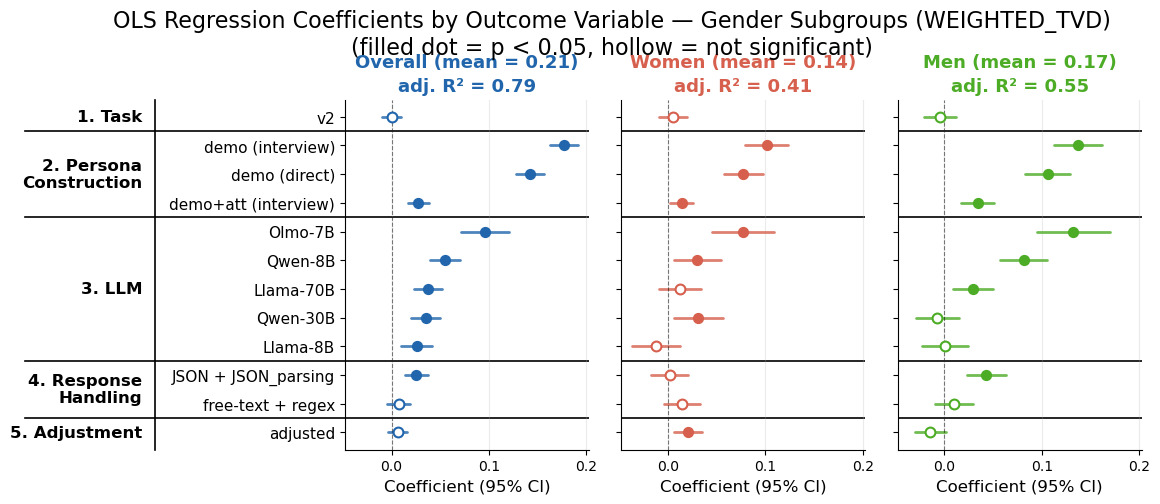

In [38]:
# ---- Same grouped y-axis, now broken down by gender subgroup for `subgroup_metric` ----
colors = ['#2166ac', '#d6604d', '#4dac26', '#b35806']
GROUP_HEADERS = {
    'Task': '1. Task',
    'Persona': '2. Persona\nConstruction',
    'LLM': '3. LLM',
    'Response_Handling': '4. Response\nHandling',
    'Adjustment': '5. Adjustment',
}
GROUP_VAR_ORDER = ['Task', 'Persona', 'LLM', 'Response_Handling', 'Adjustment']

def non_ref_variants(var):
    means = plot_df.groupby(var)[main_metric].mean()
    return list(means[means.index != refs[var]].sort_values(ascending=False).index)

Y_GROUPS = [(GROUP_HEADERS[var], non_ref_variants(var)) for var in GROUP_VAR_ORDER]

ordered_items = [it for _, its in Y_GROUPS for it in its]
n_vars = len(ordered_items)
y_pos = {it: n_vars - 1 - i for i, it in enumerate(ordered_items)}

fig, axes = plt.subplots(1, len(regs_gender), figsize=(16.5 * len(regs_gender) / 4, max(4.8, n_vars * 0.35 + 0.7)),
                         sharey=True, sharex=True)

for ax, label, color, reg in zip(axes, model_labels_gender, colors, regs_gender):
    subset = coef_df_gender[coef_df_gender['model'] == label].set_index('label')
    for var in ordered_items:
        if var not in subset.index:
            continue
        row = subset.loc[var]
        y = y_pos[var]
        sig = row['pvalue'] < 0.05
        ax.plot([row['ci_low'], row['ci_high']], [y, y],
                color=color, linewidth=2, alpha=0.8, solid_capstyle='round')
        if sig:
            ax.scatter(row['coef'], y, color=color, s=50, zorder=5)
        else:
            ax.scatter(row['coef'], y, facecolors='white', edgecolors=color,
                       linewidths=1.5, s=50, zorder=5)

    ax.axvline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
    ax.set_title(f'{label}\nadj. R² = {reg.rsquared_adj:.2f}', color=color,
                 fontsize=13, fontweight='bold', linespacing=1.4)
    ax.set_xlabel('Coefficient (95% CI)', fontsize=12)
    ax.grid(axis='x', alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].set_yticks([y_pos[it] for it in ordered_items])
axes[0].set_yticklabels(ordered_items, fontsize=11)
axes[0].set_ylim(-0.6, n_vars - 0.4)

# reserve a (modest) left gutter for the horizontal group labels
fig.tight_layout(rect=[0.18, 0, 1, 0.96])
fig.canvas.draw()                       # realize tick-label positions

pos = axes[0].get_position()
inv = fig.transFigure.inverted()
rend = fig.canvas.get_renderer()

# left edge of the inner tick labels (figure coords)
inner_left = min(t.get_window_extent(rend).transformed(inv).x0
                 for t in axes[0].get_yticklabels())

divider_x   = inner_left - 0.012        # divider just left of the inner labels
label_right = divider_x - 0.010         # group labels end just left of the divider
sep_left    = divider_x - 0.105         # separators start left of the group labels

trans = mtransforms.blended_transform_factory(fig.transFigure, axes[0].transData)

# (2) horizontal group labels, RIGHT-aligned right next to the inner labels
for header, its in Y_GROUPS:
    yc = np.mean([y_pos[it] for it in its])
    axes[0].text(label_right, yc, header, transform=trans, rotation=0,
                 ha='right', va='center', fontsize=12, fontweight='bold',
                 clip_on=False)
    
boundaries, cum = [], 0
for _, its in Y_GROUPS[:-1]:
    cum += len(its)
    boundaries.append((n_vars - 1 - cum) + 0.5)

# (3) horizontal separators extended across the gutter (through the group labels)
for b in boundaries:
    fig.add_artist(matplotlib.lines.Line2D([sep_left, pos.x0], [b, b],
                   transform=trans, color='black', linewidth=1.2))  # gutter segment
    for ax in axes:
        ax.axhline(b, color='black', linewidth=1.2, zorder=1)       # panel segments

# vertical divider between group labels and inner labels (height = plot height)
fig.add_artist(matplotlib.lines.Line2D([divider_x, divider_x], [pos.y0, pos.y1],
               transform=fig.transFigure, color='black', linewidth=1.2))

fig.suptitle(f'OLS Regression Coefficients by Outcome Variable — Gender Subgroups ({subgroup_metric.upper()})\n'
             '(filled dot = p < 0.05, hollow = not significant)',
             fontsize=16, y=1.02, x = 0.55)

plt.savefig(f'results/pre_election/regression_lollipop_gender_{subgroup_metric}_v2.pdf', dpi=150, bbox_inches='tight')
plt.show()

### create a similar plot but for political leaning (ideology) subgroups
there are more subgroups than fit in one row of 4, so wrap onto extra rows
also works for any metric of interest (F1 or TVD) via the shared subgroup_metric

In [39]:
# for leah's poster: overall, extreme lib, moderate, extreme conservative 
'''
plot_df = plot_df[['Inference', 'LLM', 'Behavior_Proc', 'simulated_responses',
       'valid_responses', 'accuracy', 'weighted_accuracy', 'macro_avg_f1',
       'f1_Trump', 'f1_Harris', 'f1_Non_voter', 'Task', 'Persona_Information',
       'Persona_Format', 'Persona', 'Response_Handling', 'weighted_f1',
       'weighted_tvd', 'weighted_std', 'weighted10_avg', 'weighted10_std',
       'weighted50_avg', 'weighted50_std', 'weighted100_avg',
       'weighted100_std', 'weighted_f1_gender_a man',
       'weighted_tvd_gender_a man', 'weighted_f1_gender_a woman',
       'weighted_tvd_gender_a woman', 'weighted_f1_gender_nonbinary',
       'weighted_tvd_gender_nonbinary', 
       # 'weighted_f1_ideology_conservative',
       # 'weighted_tvd_ideology_conservative',
       'weighted_f1_ideology_extremely conservative',
       'weighted_tvd_ideology_extremely conservative',
       'weighted_f1_ideology_extremely liberal',
       'weighted_tvd_ideology_extremely liberal',
       # 'weighted_f1_ideology_liberal', 'weighted_tvd_ideology_liberal',
       'weighted_f1_ideology_moderate', 'weighted_tvd_ideology_moderate',
       # 'weighted_f1_ideology_slightly conservative',
       # 'weighted_tvd_ideology_slightly conservative',
       # 'weighted_f1_ideology_slightly liberal',
       # 'weighted_tvd_ideology_slightly liberal',
                   'Adjustment']]
'''

"\nplot_df = plot_df[['Inference', 'LLM', 'Behavior_Proc', 'simulated_responses',\n       'valid_responses', 'accuracy', 'weighted_accuracy', 'macro_avg_f1',\n       'f1_Trump', 'f1_Harris', 'f1_Non_voter', 'Task', 'Persona_Information',\n       'Persona_Format', 'Persona', 'Response_Handling', 'weighted_f1',\n       'weighted_tvd', 'weighted_std', 'weighted10_avg', 'weighted10_std',\n       'weighted50_avg', 'weighted50_std', 'weighted100_avg',\n       'weighted100_std', 'weighted_f1_gender_a man',\n       'weighted_tvd_gender_a man', 'weighted_f1_gender_a woman',\n       'weighted_tvd_gender_a woman', 'weighted_f1_gender_nonbinary',\n       'weighted_tvd_gender_nonbinary', \n       # 'weighted_f1_ideology_conservative',\n       # 'weighted_tvd_ideology_conservative',\n       'weighted_f1_ideology_extremely conservative',\n       'weighted_tvd_ideology_extremely conservative',\n       'weighted_f1_ideology_extremely liberal',\n       'weighted_tvd_ideology_extremely liberal',\n       

In [40]:
ideology_cols = [c for c in plot_df.columns if c.startswith(f'{subgroup_metric}_ideology_')]
plot_df_ideology = plot_df.rename({main : main.replace('extremely', 'extrm') for main in ideology_cols}, axis = 1)
plot_df_ideology = plot_df_ideology.rename({main : main.replace('slightly', 'slight') for main in ideology_cols}, axis = 1)

ideology_cols = [c for c in plot_df_ideology.columns if c.startswith(f'{subgroup_metric}_ideology_')]
plot_df_ideology = plot_df_ideology.rename({main : main.replace('liberal', 'lib') for main in ideology_cols}, axis = 1)
plot_df_ideology = plot_df_ideology.rename({main : main.replace('conservative', 'conserv') for main in ideology_cols}, axis = 1)
ideology_cols = [c for c in plot_df_ideology.columns if c.startswith(f'{subgroup_metric}_ideology_')]

In [41]:
# discover the ideology subgroup columns for the chosen metric rather than hardcoding their names
ideology_categories = {c: c.replace(f'{subgroup_metric}_ideology_', '') for c in ideology_cols}
ideology_rename = {
    c: f'{subgroup_metric.upper()}_' + cat.replace(' ', '_')
    for c, cat in ideology_categories.items()
}

plot_df_ideology = plot_df_ideology.rename(columns=ideology_rename)

dep_vars_ideology = [subgroup_metric] + list(ideology_rename.values())
model_labels_ideology_raw = ['Overall'] + [
    f'{cat.title()}' for cat in ideology_categories.values()
]

In [42]:
model_labels_ideology_raw = reoder_ideology_order(model_labels_ideology_raw)
dep_vars_ideology = reoder_ideology_order(dep_vars_ideology)

In [43]:
regs_ideology = []
for dep_var in dep_vars_ideology:
    regs_ideology.append(ols(f"{dep_var} ~ {formula}",
          data = plot_df_ideology).fit(cov_type = 'HC3'))

In [44]:
all_coefs_ideology = []
for reg, label in zip(regs_ideology, model_labels_ideology_raw):
    ci = reg.conf_int()
    df_c = pd.DataFrame({
        'coef': reg.params,
        'ci_low': ci[0],
        'ci_high': ci[1],
        'pvalue': reg.pvalues,
        'model': label
    })
    df_c = df_c[df_c.index != 'Intercept']
    all_coefs_ideology.append(df_c)

coef_df_ideology = pd.concat(all_coefs_ideology).reset_index().rename(columns={'index': 'variable'})
coef_df_ideology['label'] = coef_df_ideology['variable'].apply(clean_name)

In [45]:
ideology_f1_dict = {
    raw: f'{raw} (mean = {plot_df_ideology[dep_var].mean():.2f})'
    for raw, dep_var in zip(model_labels_ideology_raw, dep_vars_ideology)
}

coef_df_ideology['model'] = [ideology_f1_dict[i] for i in coef_df_ideology['model']]
model_labels_ideology = [ideology_f1_dict[raw] for raw in model_labels_ideology_raw]

In [46]:
def plot_grouped_lollipop(specs, coef_df, Y_GROUPS, ordered_items, y_pos, n_vars, boundaries,
                           suptitle, savepath, ncols_max=4):
    """Grid of lollipop coefficient panels, one per (label, color, reg) in `specs`,
    wrapping onto additional rows so each row has at most `ncols_max` subfigures."""
    n_panels = len(specs)
    ncols = min(n_panels, ncols_max)
    nrows = int(np.ceil(n_panels / ncols_max))

    fig, axes = plt.subplots(nrows, ncols,
                              figsize=(15.5 * ncols / ncols_max, nrows * max(4.8, n_vars * 0.35 + 1.2)),
                              sharey=True, sharex=True, squeeze=False)

    for idx in range(nrows * ncols):
        r, c = divmod(idx, ncols)
        ax = axes[r][c]
        if idx >= n_panels:
            ax.axis('off')
            continue
        label, color, reg = specs[idx]
        subset = coef_df[coef_df['model'] == label].set_index('label')
        for var in ordered_items:
            if var not in subset.index:
                continue
            row = subset.loc[var]
            y = y_pos[var]
            sig = row['pvalue'] < 0.05
            ax.plot([row['ci_low'], row['ci_high']], [y, y],
                    color=color, linewidth=2, alpha=0.8, solid_capstyle='round')
            if sig:
                ax.scatter(row['coef'], y, color=color, s=50, zorder=5)
            else:
                ax.scatter(row['coef'], y, facecolors='white', edgecolors=color,
                           linewidths=1.5, s=50, zorder=5)

        ax.axvline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
        # break the mean annotation onto its own line so long subgroup names
        # (e.g. "F1 Extremely Conservative (mean = 0.23)") don't collide with
        # the neighboring panel's title
        if ' (mean' in label:
            title_name, mean_part = label.split(' (mean', 1)
            mean_part = '(mean' + mean_part
        else:
            title_name, mean_part = label, ''
        title = title_name + (f' {mean_part}' if mean_part else '') \
                + f'\nadj. R² = {reg.rsquared_adj:.2f}'
        ax.set_title(title, color=color, fontsize=11, fontweight='bold', linespacing=1.4)
        ax.set_xlabel('Coefficient (95% CI)', fontsize=12)
        ax.grid(axis='x', alpha=0.25)
        ax.spines[['top', 'right']].set_visible(False)

    for r in range(nrows):
        axes[r][0].set_yticks([y_pos[it] for it in ordered_items])
        axes[r][0].set_yticklabels(ordered_items, fontsize=11)
        axes[r][0].set_ylim(-0.6, n_vars - 0.4)

    # reserve a (modest) left gutter for the horizontal group labels
    fig.tight_layout(rect=[0.18, 0, 1, 0.96])
    fig.canvas.draw()                       # realize tick-label positions
    inv = fig.transFigure.inverted()
    rend = fig.canvas.get_renderer()

    for r in range(nrows):
        ax0 = axes[r][0]
        pos = ax0.get_position()

        # left edge of the inner tick labels (figure coords)
        inner_left = min(t.get_window_extent(rend).transformed(inv).x0
                         for t in ax0.get_yticklabels())

        divider_x   = inner_left - 0.012        # divider just left of the inner labels
        label_right = divider_x - 0.010         # group labels end just left of the divider
        sep_left    = divider_x - 0.105         # separators start left of the group labels

        trans = mtransforms.blended_transform_factory(fig.transFigure, ax0.transData)

        # horizontal group labels, RIGHT-aligned right next to the inner labels
        for header, its in Y_GROUPS:
            yc = np.mean([y_pos[it] for it in its])
            ax0.text(label_right, yc, header, transform=trans, rotation=0,
                     ha='right', va='center', fontsize=12, fontweight='bold',
                     clip_on=False)

        # horizontal separators extended across the gutter (through the group labels)
        for b in boundaries:
            fig.add_artist(matplotlib.lines.Line2D([sep_left, pos.x0], [b, b],
                           transform=trans, color='black', linewidth=1.2))  # gutter segment
            for c in range(ncols):
                axes[r][c].axhline(b, color='black', linewidth=1.2, zorder=1)  # panel segments

        # vertical divider between group labels and inner labels (height = row's plot height)
        fig.add_artist(matplotlib.lines.Line2D([divider_x, divider_x], [pos.y0, pos.y1],
                       transform=fig.transFigure, color='black', linewidth=1.2))

    fig.suptitle(suptitle, fontsize=16, y=1.05, x=0.55)
    plt.savefig(savepath, dpi=150, bbox_inches='tight')
    plt.show()

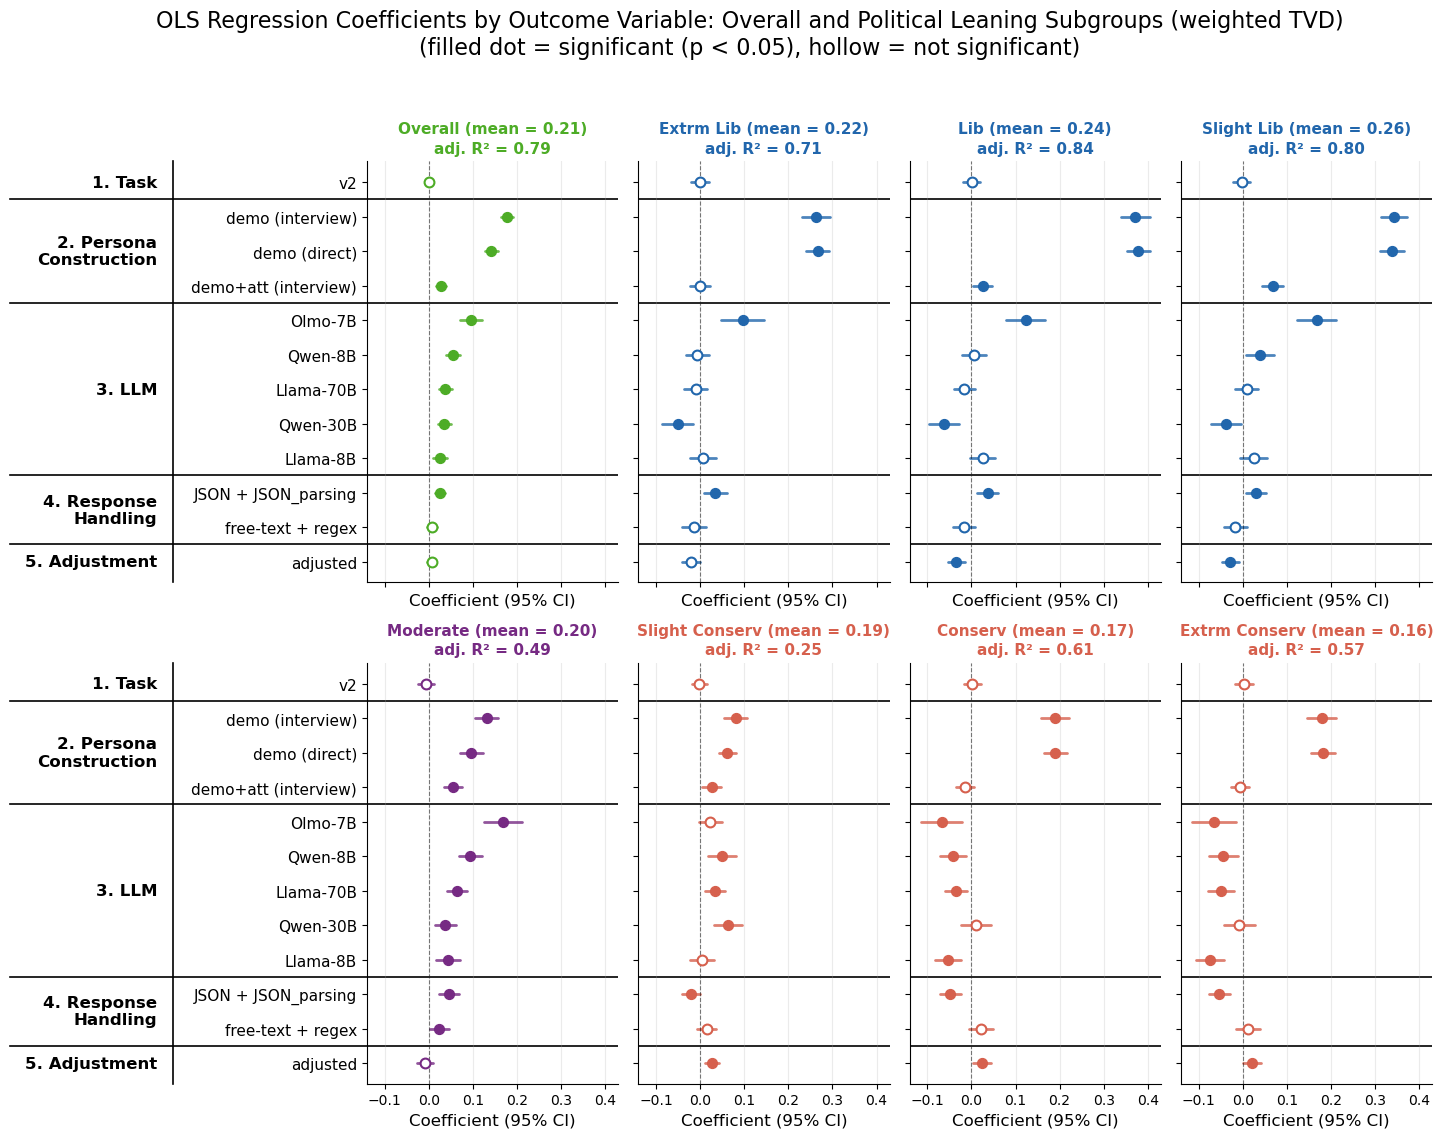

In [47]:
IDEOLOGY_COLORS = {
    'conservative': '#d6604d',  # red — all conservative-leaning subgroups
    'liberal': '#2166ac',       # blue — all liberal-leaning subgroups
    'moderate': '#762a83',      # purple — moderate
    'overall': '#4dac26',       # green — overall metric
}

specs_ideology = list(zip(
    model_labels_ideology,
    [ideology_color(raw) for raw in model_labels_ideology_raw],
    regs_ideology,
))

if subgroup_metric == 'weighted_tvd':
    metric_label = 'weighted TVD'
else:
    metric_label = subgroup_metric.replace('_', ' ').replace('f', 'F')

plot_grouped_lollipop(
    specs_ideology, coef_df_ideology, Y_GROUPS, ordered_items, y_pos, n_vars, boundaries,
    suptitle=f'OLS Regression Coefficients by Outcome Variable: Overall and Political Leaning Subgroups ({metric_label})\n'
             '(filled dot = significant (p < 0.05), hollow = not significant)',
    savepath=f'results/pre_election/regression_lollipop_ideology_{subgroup_metric}_{main_metric}_v2.pdf',
)

In [48]:
Stargazer(regs_ideology)

In [49]:
dep_vars_ideology

['weighted_tvd',
 'WEIGHTED_TVD_extrm_lib',
 'WEIGHTED_TVD_lib',
 'WEIGHTED_TVD_slight_lib',
 'WEIGHTED_TVD_moderate',
 'WEIGHTED_TVD_slight_conserv',
 'WEIGHTED_TVD_conserv',
 'WEIGHTED_TVD_extrm_conserv']

In [50]:
agg_results_df

,questionnaire_item_id,response_type,persona_format,sample,model_id,parsing_method,simulated_responses,valid_responses,accuracy,weighted_accuracy,...,adjusted_weighted_tvd_ideology_moderate,nonadjusted_weighted_tvd_ideology_moderate,adjusted_weighted_f1_ideology_slightly conservative,nonadjusted_weighted_f1_ideology_slightly conservative,adjusted_weighted_tvd_ideology_slightly conservative,nonadjusted_weighted_tvd_ideology_slightly conservative,adjusted_weighted_f1_ideology_slightly liberal,nonadjusted_weighted_f1_ideology_slightly liberal,adjusted_weighted_tvd_ideology_slightly liberal,nonadjusted_weighted_tvd_ideology_slightly liberal
0,1,jsonResponse,demogrFirstPerson,0,Llama-3.1-8B-Instruct,jsonParsing,25355,25355,0.510392,0.525109,...,0.258451,0.371012,0.546364,0.537122,0.123127,0.110078,0.501261,0.420632,0.480081,0.578927
1,1,jsonResponse,demogrFirstPerson,0,Llama-3.3-70B-Instruct,jsonParsing,25355,25355,0.535831,0.538787,...,0.211938,0.289105,0.533803,0.528700,0.200065,0.116279,0.563793,0.505534,0.390708,0.480843
2,1,jsonResponse,demogrFirstPerson,0,Olmo-3-7B-Instruct,jsonParsing,25355,25355,0.440032,0.439604,...,0.598726,0.624514,0.500125,0.493573,0.265309,0.281395,0.281890,0.214116,0.744047,0.781992
3,1,jsonResponse,demogrFirstPerson,0,Olmo-3.1-32B-Instruct,jsonParsing,25355,25355,0.515283,0.521447,...,0.140405,0.221012,0.545377,0.524535,0.138609,0.080233,0.594110,0.529471,0.327463,0.415326
4,1,jsonResponse,demogrFirstPerson,0,Qwen3-VL-30B-A3B-Instruct,jsonParsing,25355,25355,0.537961,0.534316,...,0.172277,0.199611,0.509939,0.512535,0.284801,0.199612,0.625385,0.568441,0.298977,0.383908
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,2,openResponse,interview,0,Olmo-3.1-32B-Instruct,regex,25355,23737,NaN,NaN,...,0.150852,0.111576,0.671750,0.678287,0.113689,0.115698,0.828960,0.859828,0.051525,0.039272
140,2,openResponse,interview,0,Qwen3-VL-30B-A3B-Instruct,LLMjudge,25355,25355,0.802011,0.769048,...,0.209401,0.158949,0.658138,0.654074,0.134865,0.115116,0.814936,0.841627,0.116739,0.100383
141,2,openResponse,interview,0,Qwen3-VL-30B-A3B-Instruct,regex,25355,25277,NaN,NaN,...,0.211462,0.160700,0.656813,0.652913,0.135285,0.115698,0.814936,0.841627,0.116739,0.100383
142,2,openResponse,interview,0,Qwen3-VL-8B-Instruct,LLMjudge,25355,25355,0.781266,0.762095,...,0.194046,0.221401,0.616328,0.603008,0.257760,0.265891,0.777683,0.790379,0.131611,0.130268
